# Auditoría de solapamiento: entrenamiento de PosFormer vs. CROHME 2016 y 2019

Este notebook verifica si existen instancias de los tests CROHME 2016 o CROHME 2019 dentro del conjunto de entrenamiento utilizado por PosFormer.

## Niveles de verificación

1. **Identificador exacto:** mismo ID en entrenamiento y test.
2. **Archivo exacto:** mismo SHA-256 de los bytes del BMP, aunque cambie el nombre.
3. **Píxeles exactos:** mismas dimensiones y mismos píxeles en escala de grises, aunque cambie la codificación del archivo.
4. **Candidatos visualmente cercanos:** huella perceptual dHash con distancia de Hamming pequeña, seguida de revisión visual.
5. **Ground truth compartido:** se reporta por separado y **no se interpreta como la misma instancia**, porque distintas personas pueden escribir la misma expresión.

El notebook es descriptivo. No entrena modelos, no modifica datos y no utiliza CROHME 2016 o 2019 para ajustar parámetros, umbrales o reglas de normalización.

## Restricción metodológica

CROHME 2016 y CROHME 2019 están reservados para evaluación final. Esta auditoría se limita a comprobar separación respecto del entrenamiento. Los umbrales experimentales de la cascada no se recalculan y los hallazgos no se usan para optimizar el sistema.

La eliminación de `\limits` se emplea únicamente en una comparación auxiliar de anotaciones. No interviene en la detección principal de instancias, que se basa en identificadores e imágenes.

## 1. Importaciones y configuración

La búsqueda perceptual usa un umbral fijo y conservador como filtro de candidatos. Una distancia pequeña no demuestra duplicación: todos los candidatos deben revisarse visualmente.

In [1]:
# Librerías para rutas, hashes, tablas, imágenes y visualización.
from pathlib import Path
from collections import Counter
import hashlib
import json
import math

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Parámetros diagnósticos fijos; no son hiperparámetros del modelo.
UMBRAL_HAMMING_DHASH = 4
MAX_CANDIDATOS_POR_IMAGEN_TEST = 3
MAX_CANDIDATOS_A_VISUALIZAR = 20
SEMILLA = 42
REMUESTREO_LANCZOS = (
    Image.Resampling.LANCZOS
    if hasattr(Image, "Resampling")
    else Image.LANCZOS
)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_rows", 100)

## 2. Localización del repositorio y rutas

Se comprueba la existencia de las tres particiones de PosFormer antes de continuar.

In [2]:
# Localiza la raíz mediante los caption.txt requeridos.
def localizar_raiz(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    inicio = inicio.resolve()
    for raiz in [inicio, *inicio.parents]:
        requeridos = [
            raiz / "data" / "Modelo2" / "train" / "caption.txt",
            raiz / "data" / "Modelo2" / "2016" / "caption.txt",
            raiz / "data" / "Modelo2" / "2019" / "caption.txt",
        ]
        if all(ruta.is_file() for ruta in requeridos):
            return raiz
    raise FileNotFoundError(
        "No se encontraron train, 2016 y 2019 de PosFormer desde el directorio actual."
    )

RAIZ = localizar_raiz()
MODELO2 = RAIZ / "data" / "Modelo2"
RESULTADOS_DIR = RAIZ / "Cascada" / "00_analisis_exploratorio" / "resultados"

RUTAS = {
    "train": {
        "dir": MODELO2 / "train",
        "caption": MODELO2 / "train" / "caption.txt",
        "img": MODELO2 / "train" / "img",
        "lg": MODELO2 / "train" / "symLg",
    },
    "2016": {
        "dir": MODELO2 / "2016",
        "caption": MODELO2 / "2016" / "caption.txt",
        "img": MODELO2 / "2016" / "img",
        "lg": MODELO2 / "2016" / "symLg",
    },
    "2019": {
        "dir": MODELO2 / "2019",
        "caption": MODELO2 / "2019" / "caption.txt",
        "img": MODELO2 / "2019" / "img",
        "lg": MODELO2 / "2019" / "symLg",
    },
}

for particion, rutas in RUTAS.items():
    print(f"{particion}: {rutas['dir'].relative_to(RAIZ)}")
    for tipo in ["caption", "img", "lg"]:
        print(f"  {tipo:7s} existe={rutas[tipo].exists()}")

train: data/Modelo2/train
  caption existe=True
  img     existe=True
  lg      existe=True
2016: data/Modelo2/2016
  caption existe=True
  img     existe=True
  lg      existe=True
2019: data/Modelo2/2019
  caption existe=True
  img     existe=True
  lg      existe=True


## 3. Lectura de anotaciones e inventario

Cada línea debe contener un ID y una referencia LaTeX separados por tabulación. La auditoría se detiene si hay IDs duplicados o si no existe correspondencia completa entre anotaciones e imágenes.

In [3]:
# Lee caption.txt conservando el orden y el ground truth original.
def leer_caption(ruta, particion):
    registros = []
    errores = []
    with ruta.open("r", encoding="utf-8-sig") as archivo:
        for numero_linea, linea_cruda in enumerate(archivo, start=1):
            linea = linea_cruda.rstrip("\r\n")
            if not linea.strip():
                errores.append(
                    {"particion": particion, "linea": numero_linea, "motivo": "vacía"}
                )
                continue
            if "\t" not in linea:
                errores.append(
                    {
                        "particion": particion,
                        "linea": numero_linea,
                        "motivo": "sin tabulador",
                    }
                )
                continue
            identificador, latex = linea.split("\t", maxsplit=1)
            registros.append(
                {
                    "particion": particion,
                    "orden_caption": len(registros),
                    "linea_caption": numero_linea,
                    "id": identificador.strip(),
                    "latex": latex.strip(),
                }
            )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        repetidos = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs duplicados en {particion}: {repetidos[:10]}")
    return tabla, pd.DataFrame(errores)

tablas = {}
errores = {}
inventarios = []

for particion, rutas in RUTAS.items():
    tabla, tabla_errores = leer_caption(rutas["caption"], particion)
    imagenes = sorted(rutas["img"].glob("*.bmp"))
    archivos_lg = sorted(rutas["lg"].glob("*.lg"))

    mapa_imagenes = {ruta.stem: ruta for ruta in imagenes}
    ids_caption = set(tabla["id"])
    ids_imagen = set(mapa_imagenes)
    ids_lg = {ruta.stem for ruta in archivos_lg}

    tabla["ruta_imagen"] = tabla["id"].map(mapa_imagenes)
    tablas[particion] = tabla
    errores[particion] = tabla_errores

    inventarios.append(
        {
            "particion": particion,
            "anotaciones": len(tabla),
            "ids_unicos": tabla["id"].nunique(),
            "imagenes_bmp": len(imagenes),
            "archivos_lg": len(archivos_lg),
            "lineas_con_error": len(tabla_errores),
            "caption_sin_imagen": len(ids_caption - ids_imagen),
            "imagen_sin_caption": len(ids_imagen - ids_caption),
            "caption_sin_lg": len(ids_caption - ids_lg),
            "lg_sin_caption": len(ids_lg - ids_caption),
        }
    )

df_inventario = pd.DataFrame(inventarios).set_index("particion")
display(df_inventario)

columnas_discrepancia = [
    "lineas_con_error",
    "caption_sin_imagen",
    "imagen_sin_caption",
    "caption_sin_lg",
    "lg_sin_caption",
]
if df_inventario[columnas_discrepancia].to_numpy().sum() != 0:
    raise ValueError("Existen discrepancias de inventario; revíselas antes de comparar.")

,anotaciones,ids_unicos,imagenes_bmp,archivos_lg,lineas_con_error,caption_sin_imagen,imagen_sin_caption,caption_sin_lg,lg_sin_caption
particion,,,,,,,,,
train,8834,8834,8834,8834,0,0,0,0,0
2016,1147,1147,1147,1147,0,0,0,0,0
2019,1199,1199,1199,1199,0,0,0,0,0


## 4. Coincidencias de identificadores

La igualdad de IDs es la primera señal de posible solapamiento, pero se confirma después con el contenido visual.

In [4]:
# Compara por separado entrenamiento contra cada test.
ids_train = set(tablas["train"]["id"])
solapamientos_id = {}

for anio in ["2016", "2019"]:
    ids_test = set(tablas[anio]["id"])
    compartidos = sorted(ids_train & ids_test)
    solapamientos_id[anio] = compartidos
    print(f"Train vs. {anio}: {len(compartidos)} IDs compartidos")
    display(pd.DataFrame({"id_compartido": compartidos}).head(100))

Train vs. 2016: 0 IDs compartidos


,id_compartido


Train vs. 2019: 0 IDs compartidos


,id_compartido


## 5. Huellas exactas de archivos y píxeles

- `sha256_archivo` detecta BMP exactamente iguales byte a byte.
- `sha256_pixeles` convierte a escala de grises e incorpora las dimensiones antes de calcular la huella. Así puede detectar contenido raster idéntico aunque el encabezado o la codificación del BMP cambien.

In [5]:
# Calcula huellas reproducibles sin modificar las imágenes.
def sha256_archivo(ruta, tamano_bloque=1024 * 1024):
    digest = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        while True:
            bloque = archivo.read(tamano_bloque)
            if not bloque:
                break
            digest.update(bloque)
    return digest.hexdigest()

def sha256_pixeles(ruta):
    with Image.open(ruta) as imagen:
        gris = np.asarray(imagen.convert("L"), dtype=np.uint8)
    digest = hashlib.sha256()
    digest.update(np.asarray(gris.shape, dtype=np.int64).tobytes())
    digest.update(gris.tobytes())
    return digest.hexdigest()

def metadatos_y_hashes(ruta):
    with Image.open(ruta) as imagen:
        ancho, alto = imagen.size
        modo = imagen.mode
    return {
        "ancho": ancho,
        "alto": alto,
        "modo": modo,
        "sha256_archivo": sha256_archivo(ruta),
        "sha256_pixeles": sha256_pixeles(ruta),
    }

# Esta celda realiza el trabajo más costoso al ejecutarse: lee cada BMP una vez.
for particion, tabla in tablas.items():
    caracteristicas = pd.DataFrame(
        [metadatos_y_hashes(ruta) for ruta in tabla["ruta_imagen"]]
    )
    tablas[particion] = pd.concat(
        [tabla.reset_index(drop=True), caracteristicas],
        axis=1,
    )

display(
    pd.DataFrame(
        {
            particion: {
                "muestras": len(tabla),
                "hashes_archivo_unicos": tabla["sha256_archivo"].nunique(),
                "hashes_pixeles_unicos": tabla["sha256_pixeles"].nunique(),
            }
            for particion, tabla in tablas.items()
        }
    ).T
)

,muestras,hashes_archivo_unicos,hashes_pixeles_unicos
train,8834,8792,8792
2016,1147,1147,1147
2019,1199,1199,1199


## 6. Solapamientos exactos de imagen

Los cruces se hacen por huella, no por nombre. Se conserva el ID y el ground truth de ambas particiones para revisar cualquier coincidencia.

In [6]:
# Construye cruces exactos train-test para cada año.
def cruzar_por_hash(train, test, columna_hash, anio):
    columnas_train = [
        "id", "latex", "ruta_imagen", "ancho", "alto", columna_hash
    ]
    columnas_test = [
        "id", "latex", "ruta_imagen", "ancho", "alto", columna_hash
    ]

    izquierda = train[columnas_train].rename(
        columns={
            "id": "id_train",
            "latex": "latex_train",
            "ruta_imagen": "ruta_train",
            "ancho": "ancho_train",
            "alto": "alto_train",
        }
    )
    derecha = test[columnas_test].rename(
        columns={
            "id": f"id_{anio}",
            "latex": f"latex_{anio}",
            "ruta_imagen": f"ruta_{anio}",
            "ancho": f"ancho_{anio}",
            "alto": f"alto_{anio}",
        }
    )

    cruce = izquierda.merge(
        derecha,
        on=columna_hash,
        how="inner",
        validate="many_to_many",
    )
    cruce["mismo_id"] = cruce["id_train"] == cruce[f"id_{anio}"]
    cruce["mismo_ground_truth"] = (
        cruce["latex_train"] == cruce[f"latex_{anio}"]
    )
    return cruce

solapamientos_exactos = {}

for anio in ["2016", "2019"]:
    por_archivo = cruzar_por_hash(
        tablas["train"], tablas[anio], "sha256_archivo", anio
    )
    por_pixeles = cruzar_por_hash(
        tablas["train"], tablas[anio], "sha256_pixeles", anio
    )
    solapamientos_exactos[(anio, "archivo")] = por_archivo
    solapamientos_exactos[(anio, "pixeles")] = por_pixeles

    print(f"\nTrain vs. {anio}")
    print(f"  Pares con archivo idéntico: {len(por_archivo)}")
    print(f"  Pares con píxeles idénticos: {len(por_pixeles)}")
    display(por_pixeles.head(100))


Train vs. 2016
  Pares con archivo idéntico: 0
  Pares con píxeles idénticos: 0


,id_train,latex_train,ruta_train,ancho_train,alto_train,sha256_pixeles,id_2016,latex_2016,ruta_2016,ancho_2016,alto_2016,mismo_id,mismo_ground_truth



Train vs. 2019
  Pares con archivo idéntico: 0
  Pares con píxeles idénticos: 0


,id_train,latex_train,ruta_train,ancho_train,alto_train,sha256_pixeles,id_2019,latex_2019,ruta_2019,ancho_2019,alto_2019,mismo_id,mismo_ground_truth


## 7. Comparación auxiliar de ground truth

Compartir la misma anotación no implica que se repita una instancia. Esta sección solo cuantifica expresiones matemáticas comunes y mantiene esa evidencia separada de los hashes visuales.

Se muestran tanto la comparación estricta como la comparación tras retirar exclusivamente `\limits`.

In [7]:
# Aplica la normalización conservadora únicamente a la comparación auxiliar.
def normalizar_limits(secuencia):
    return " ".join(
        token for token in str(secuencia).split()
        if token != r"\limits"
    )

for particion, tabla in tablas.items():
    tabla["latex_sin_limits"] = tabla["latex"].map(normalizar_limits)

resumen_ground_truth = []

for anio in ["2016", "2019"]:
    train = tablas["train"]
    test = tablas[anio]

    latex_train = set(train["latex"])
    latex_norm_train = set(train["latex_sin_limits"])

    test_mismo_latex = test["latex"].isin(latex_train)
    test_mismo_latex_norm = test["latex_sin_limits"].isin(latex_norm_train)

    resumen_ground_truth.append(
        {
            "comparacion": f"train vs. {anio}",
            "referencias_unicas_compartidas_estrictas": len(
                set(test["latex"]) & latex_train
            ),
            "muestras_test_con_latex_en_train": int(test_mismo_latex.sum()),
            "referencias_unicas_compartidas_sin_limits": len(
                set(test["latex_sin_limits"]) & latex_norm_train
            ),
            "muestras_test_con_latex_sin_limits_en_train": int(
                test_mismo_latex_norm.sum()
            ),
        }
    )

df_ground_truth = pd.DataFrame(resumen_ground_truth).set_index("comparacion")
display(df_ground_truth)

print(
    "Nota: estas coincidencias describen expresiones repetidas, "
    "no imágenes ni instancias duplicadas."
)

,referencias_unicas_compartidas_estrictas,muestras_test_con_latex_en_train,referencias_unicas_compartidas_sin_limits,muestras_test_con_latex_sin_limits_en_train
comparacion,,,,
train vs. 2016,18,20,18,20
train vs. 2019,3,4,3,4


Nota: estas coincidencias describen expresiones repetidas, no imágenes ni instancias duplicadas.


## 8. Búsqueda perceptual de candidatos cercanos

dHash resume cambios horizontales de intensidad en 64 bits. La distancia de Hamming cuenta cuántos bits difieren.

Esta búsqueda sirve para encontrar candidatos que podrían haber sido recodificados, redimensionados o alterados levemente. No constituye una prueba de solapamiento y puede producir falsos positivos, especialmente en expresiones cortas o visualmente simples.

In [8]:
# Calcula un dHash de 64 bits sobre una representación pequeña de la imagen.
def dhash64(ruta):
    with Image.open(ruta) as imagen:
        gris = imagen.convert("L").resize((9, 8), REMUESTREO_LANCZOS)
        matriz = np.asarray(gris, dtype=np.uint8)

    diferencias = matriz[:, 1:] > matriz[:, :-1]
    valor = 0
    for bit in diferencias.ravel():
        valor = (valor << 1) | int(bit)
    return np.uint64(valor)

# Tabla de consulta para contar bits en cada byte de un uint64.
CONTEO_BITS_BYTE = np.array(
    [bin(valor).count("1") for valor in range(256)],
    dtype=np.uint8,
)

def distancias_hamming_vector(hash_referencia, hashes):
    xor = np.bitwise_xor(hashes, np.uint64(hash_referencia))
    bytes_xor = xor.view(np.uint8).reshape(-1, 8)
    return CONTEO_BITS_BYTE[bytes_xor].sum(axis=1)

for particion, tabla in tablas.items():
    tabla["dhash64"] = [
        dhash64(ruta) for ruta in tabla["ruta_imagen"]
    ]

print("Huellas perceptuales calculadas para las tres particiones.")

Huellas perceptuales calculadas para las tres particiones.


In [9]:
# Busca los vecinos más cercanos de cada imagen de test dentro del entrenamiento.
def buscar_candidatos_perceptuales(train, test, anio):
    hashes_train = train["dhash64"].to_numpy(dtype=np.uint64)
    registros = []

    for _, muestra_test in test.iterrows():
        distancias = distancias_hamming_vector(
            muestra_test["dhash64"],
            hashes_train,
        )
        indices_ordenados = np.argsort(distancias)

        agregados = 0
        for indice_train in indices_ordenados:
            distancia = int(distancias[indice_train])
            if distancia > UMBRAL_HAMMING_DHASH:
                break

            muestra_train = train.iloc[int(indice_train)]
            registros.append(
                {
                    "anio_test": anio,
                    "id_train": muestra_train["id"],
                    "id_test": muestra_test["id"],
                    "ruta_train": muestra_train["ruta_imagen"],
                    "ruta_test": muestra_test["ruta_imagen"],
                    "latex_train": muestra_train["latex"],
                    "latex_test": muestra_test["latex"],
                    "ancho_train": muestra_train["ancho"],
                    "alto_train": muestra_train["alto"],
                    "ancho_test": muestra_test["ancho"],
                    "alto_test": muestra_test["alto"],
                    "distancia_hamming": distancia,
                    "archivo_exacto": (
                        muestra_train["sha256_archivo"]
                        == muestra_test["sha256_archivo"]
                    ),
                    "pixeles_exactos": (
                        muestra_train["sha256_pixeles"]
                        == muestra_test["sha256_pixeles"]
                    ),
                    "mismo_ground_truth": (
                        muestra_train["latex"] == muestra_test["latex"]
                    ),
                }
            )
            agregados += 1
            if agregados >= MAX_CANDIDATOS_POR_IMAGEN_TEST:
                break

    return pd.DataFrame(registros)

candidatos_perceptuales = {
    anio: buscar_candidatos_perceptuales(
        tablas["train"],
        tablas[anio],
        anio,
    )
    for anio in ["2016", "2019"]
}

for anio, candidatos in candidatos_perceptuales.items():
    print(f"\nTrain vs. {anio}: {len(candidatos)} candidatos perceptuales")
    if not candidatos.empty:
        display(
            candidatos.sort_values(
                ["distancia_hamming", "id_test", "id_train"]
            ).head(100)
        )


Train vs. 2016: 0 candidatos perceptuales

Train vs. 2019: 2 candidatos perceptuales


,anio_test,id_train,id_test,ruta_train,ruta_test,latex_train,latex_test,ancho_train,alto_train,ancho_test,alto_test,distancia_hamming,archivo_exacto,pixeles_exactos,mismo_ground_truth
0,2019,200923-1556-179,UN19wb_1110_em_1025,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/200923-1556-179.bmp,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/2019/img/UN19wb_1110_em_1025.bmp,- \sum 0,+ 7 8,128,67,100,58,4,False,False,False
1,2019,126_leo,UN19wb_1121_em_1198,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/train/img/126_leo.bmp,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/2019/img/UN19wb_1121_em_1198.bmp,| x - \frac { p _ { n } } { q _ { n } } | \leq \frac { 1 } { q _ { n } q _ { n + 1 } } < \frac { 1 } { q _ { n } ^ { 2 } },\frac { 2 \pi } { 3 } - \frac { 4 \pi } { 9 } = \frac { 2 \pi } { 9 },548,132,410,127,4,False,False,False


## 9. Revisión visual de candidatos

La función muestra entrenamiento y test lado a lado. Si las dimensiones coinciden, añade la diferencia absoluta de píxeles; si no, la tercera vista informa que no son directamente comparables.

La revisión manual debe distinguir entre una instancia realmente repetida y dos escrituras distintas de una expresión simple.

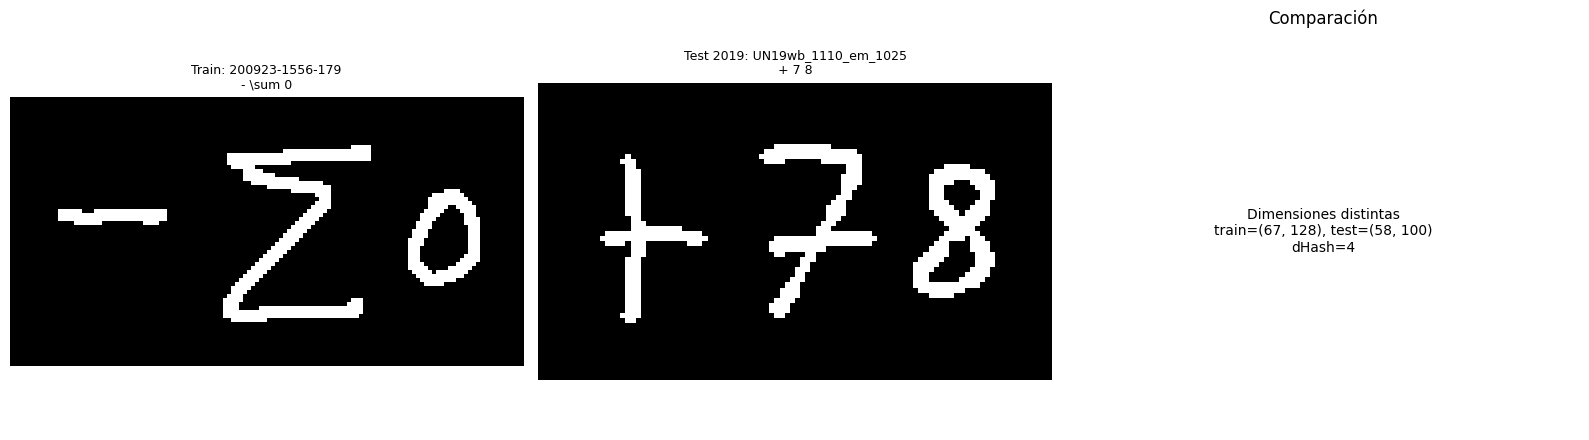

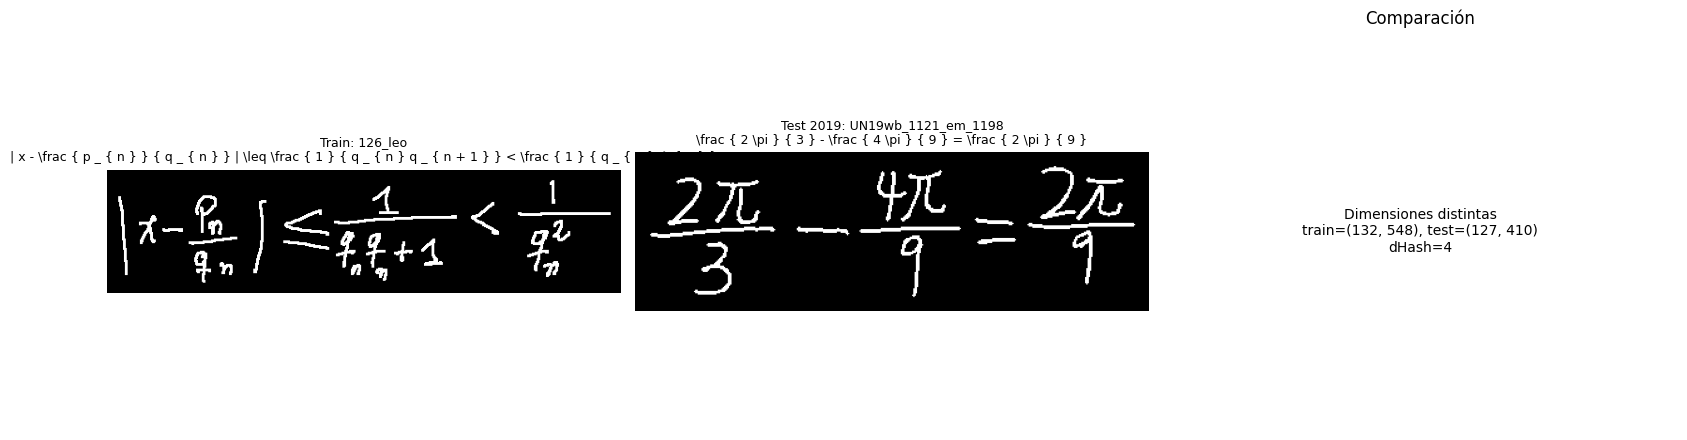

In [10]:
# Visualiza candidatos sin convertir automáticamente la similitud en una decisión.
def mostrar_candidatos(candidatos, max_casos=MAX_CANDIDATOS_A_VISUALIZAR):
    if candidatos.empty:
        print("No hay candidatos perceptuales bajo el umbral configurado.")
        return

    seleccion = candidatos.sort_values(
        ["distancia_hamming", "anio_test", "id_test", "id_train"]
    ).head(max_casos)

    for _, caso in seleccion.iterrows():
        with Image.open(caso["ruta_train"]) as imagen:
            train_img = np.asarray(imagen.convert("L"))
        with Image.open(caso["ruta_test"]) as imagen:
            test_img = np.asarray(imagen.convert("L"))

        figura, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
        ejes[0].imshow(train_img, cmap="gray", vmin=0, vmax=255)
        ejes[1].imshow(test_img, cmap="gray", vmin=0, vmax=255)

        ejes[0].set_title(
            f"Train: {caso['id_train']}\n{caso['latex_train']}",
            fontsize=9,
        )
        ejes[1].set_title(
            f"Test {caso['anio_test']}: {caso['id_test']}\n{caso['latex_test']}",
            fontsize=9,
        )

        if train_img.shape == test_img.shape:
            diferencia = np.abs(
                train_img.astype(np.int16) - test_img.astype(np.int16)
            )
            ejes[2].imshow(diferencia, cmap="magma")
            ejes[2].set_title(
                f"Diferencia absoluta\n"
                f"dHash={caso['distancia_hamming']}, "
                f"píxeles exactos={caso['pixeles_exactos']}"
            )
        else:
            ejes[2].text(
                0.5,
                0.5,
                "Dimensiones distintas\n"
                f"train={train_img.shape}, test={test_img.shape}\n"
                f"dHash={caso['distancia_hamming']}",
                ha="center",
                va="center",
            )
            ejes[2].set_title("Comparación")

        for eje in ejes:
            eje.axis("off")
        figura.tight_layout()
        plt.show()

todos_candidatos = pd.concat(
    candidatos_perceptuales.values(),
    ignore_index=True,
) if any(not df.empty for df in candidatos_perceptuales.values()) else pd.DataFrame()

mostrar_candidatos(todos_candidatos)

## 10. Tabla de decisión para revisión manual

Los candidatos perceptuales quedan con estado pendiente. Solo una inspección documentada puede clasificarlos como misma instancia, escrituras distintas o caso ambiguo.

In [11]:
# Prepara una tabla editable sin alterar las tablas originales.
if todos_candidatos.empty:
    revision_manual = pd.DataFrame(
        columns=[
            "anio_test", "id_train", "id_test", "distancia_hamming",
            "decision_visual", "observaciones",
        ]
    )
else:
    revision_manual = todos_candidatos[
        [
            "anio_test",
            "id_train",
            "id_test",
            "distancia_hamming",
            "archivo_exacto",
            "pixeles_exactos",
            "mismo_ground_truth",
        ]
    ].copy()
    revision_manual["decision_visual"] = "pendiente"
    revision_manual["observaciones"] = ""

display(revision_manual.head(100))

# Valores sugeridos para decision_visual:
# "misma instancia", "escrituras distintas", "ambiguo" o "falso positivo".

,anio_test,id_train,id_test,distancia_hamming,archivo_exacto,pixeles_exactos,mismo_ground_truth,decision_visual,observaciones
0,2019,200923-1556-179,UN19wb_1110_em_1025,4,False,False,False,pendiente,
1,2019,126_leo,UN19wb_1121_em_1198,4,False,False,False,pendiente,


## 11. Resumen de la auditoría

La conclusión principal debe basarse en IDs, SHA-256 de archivos y SHA-256 de píxeles. Los candidatos perceptuales se reportan por separado hasta completar su revisión visual.

In [12]:
# Resume por test sin mezclar evidencia exacta con evidencia aproximada.
filas_resumen = []

for anio in ["2016", "2019"]:
    candidatos = candidatos_perceptuales[anio]
    por_archivo = solapamientos_exactos[(anio, "archivo")]
    por_pixeles = solapamientos_exactos[(anio, "pixeles")]

    filas_resumen.append(
        {
            "test": anio,
            "muestras_test": len(tablas[anio]),
            "ids_compartidos_con_train": len(solapamientos_id[anio]),
            "pares_archivo_exacto": len(por_archivo),
            "imagenes_test_en_archivo_exacto": (
                por_archivo[f"id_{anio}"].nunique()
                if not por_archivo.empty else 0
            ),
            "pares_pixeles_exactos": len(por_pixeles),
            "imagenes_test_en_pixeles_exactos": (
                por_pixeles[f"id_{anio}"].nunique()
                if not por_pixeles.empty else 0
            ),
            "candidatos_perceptuales": len(candidatos),
            "candidatos_pendientes_revision": (
                len(candidatos)
                if not candidatos.empty else 0
            ),
        }
    )

df_resumen = pd.DataFrame(filas_resumen).set_index("test")
display(df_resumen)

if (
    df_resumen["ids_compartidos_con_train"].sum() == 0
    and df_resumen["pares_archivo_exacto"].sum() == 0
    and df_resumen["pares_pixeles_exactos"].sum() == 0
):
    print(
        "No se detectaron solapamientos exactos por ID, archivo o píxeles. "
        "La conclusión sobre similitudes aproximadas queda sujeta a la revisión visual."
    )
else:
    print(
        "Se detectó al menos un solapamiento exacto. "
        "Revise las tablas antes de utilizar los tests para evaluación final."
    )

,muestras_test,ids_compartidos_con_train,pares_archivo_exacto,imagenes_test_en_archivo_exacto,pares_pixeles_exactos,imagenes_test_en_pixeles_exactos,candidatos_perceptuales,candidatos_pendientes_revision
test,,,,,,,,
2016,1147,0,0,0,0,0,0,0
2019,1199,0,0,0,0,0,2,2


No se detectaron solapamientos exactos por ID, archivo o píxeles. La conclusión sobre similitudes aproximadas queda sujeta a la revisión visual.


## 12. Exportación reproducible

Esta celda guarda únicamente resultados de auditoría. No modifica los datasets ni crea parámetros para el modelo.

In [13]:
# Exporta tablas y parámetros diagnósticos cuando el usuario ejecute esta celda.
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

df_inventario.to_csv(
    RESULTADOS_DIR / "auditoria_solapamiento_posformer_inventario.csv"
)
df_ground_truth.to_csv(
    RESULTADOS_DIR / "auditoria_solapamiento_posformer_ground_truth.csv"
)
df_resumen.to_csv(
    RESULTADOS_DIR / "auditoria_solapamiento_posformer_resumen.csv"
)

for anio in ["2016", "2019"]:
    solapamientos_exactos[(anio, "archivo")].to_csv(
        RESULTADOS_DIR
        / f"auditoria_solapamiento_posformer_train_vs_{anio}_archivo.csv",
        index=False,
    )
    solapamientos_exactos[(anio, "pixeles")].to_csv(
        RESULTADOS_DIR
        / f"auditoria_solapamiento_posformer_train_vs_{anio}_pixeles.csv",
        index=False,
    )
    candidatos_perceptuales[anio].to_csv(
        RESULTADOS_DIR
        / f"auditoria_solapamiento_posformer_train_vs_{anio}_perceptual.csv",
        index=False,
    )

revision_manual.to_csv(
    RESULTADOS_DIR / "auditoria_solapamiento_posformer_revision_manual.csv",
    index=False,
)

resumen_json = {
    "objetivo": "auditar solapamientos entre train de PosFormer y tests 2016/2019",
    "parametros_diagnosticos": {
        "umbral_hamming_dhash": UMBRAL_HAMMING_DHASH,
        "max_candidatos_por_imagen_test": MAX_CANDIDATOS_POR_IMAGEN_TEST,
        "semilla": SEMILLA,
    },
    "resultados": {
        str(indice): {
            clave: int(valor)
            for clave, valor in fila.items()
        }
        for indice, fila in df_resumen.reset_index().set_index("test").to_dict(
            orient="index"
        ).items()
    },
    "interpretacion": (
        "Los hashes exactos constituyen evidencia de identidad. "
        "Los candidatos perceptuales requieren revisión visual."
    ),
}

with (
    RESULTADOS_DIR / "auditoria_solapamiento_posformer_resumen.json"
).open("w", encoding="utf-8") as archivo:
    json.dump(resumen_json, archivo, ensure_ascii=False, indent=2)

print(f"Resultados guardados en: {RESULTADOS_DIR}")

Resultados guardados en: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/00_analisis_exploratorio/resultados


## Guía de interpretación

- **ID compartido:** posible reutilización administrativa; debe contrastarse con la imagen.
- **SHA-256 de archivo compartido:** los BMP son exactamente el mismo archivo.
- **SHA-256 de píxeles compartido:** el contenido raster y las dimensiones son idénticos, aunque el archivo pueda estar codificado de otra forma.
- **dHash cercano:** candidato visual; no es prueba suficiente.
- **Ground truth compartido:** misma expresión matemática, no necesariamente la misma escritura.
- **Ausencia de coincidencias exactas:** permite afirmar que no se encontraron instancias idénticas bajo los criterios exactos aplicados, pero no demuestra por sí sola la inexistencia absoluta de versiones transformadas.
- Si se detecta un caso exacto o ambiguo, debe documentarse antes de la evaluación final; no debe eliminarse ni cambiarse silenciosamente.